In [1]:
import os
import warnings
import joblib

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from rasterio.mask import mask
from rasterio.features import geometry_mask
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    cohen_kappa_score
)

warnings.filterwarnings("ignore")

In [2]:
# -----------------------------
# Input Data
# -----------------------------

PICH_IMAGE = r"C:\Users\snvra\NISAR_Data_project\Data\Pich_SatEmb_2025\Pichavaram_Mosaic.tif"

PICH_GT = r"C:\Users\snvra\NISAR_Data_project\Data\pichhavaram_gt\pich_gt.shp" 

PICH_AOI = r"C:\Users\snvra\NISAR_Data_project\Data\pich_mang\pich_mang_mask.shp"

# -----------------------------
# Output folders
# -----------------------------

MODEL_FOLDER = r"C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Models"

MAP_FOLDER = r"C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Probability_maps"

CLASS_FOLDER = r"C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Final_Classification"

FIG_FOLDER = r"C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Figures"

RESULT_FOLDER = r"C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Accuracy_Assessment"

for folder in [
    MODEL_FOLDER,
    MAP_FOLDER,
    CLASS_FOLDER,
    FIG_FOLDER,
    RESULT_FOLDER,
]:
    os.makedirs(folder, exist_ok=True)

In [3]:
species_list = [
    "A_marina_dense",
    "A_marina_moderate",
    "A_marina_sparse",
    "Rhizophora",
]

species_short = {
    "A_marina_dense": "Dense",
    "A_marina_moderate": "Moderate",
    "A_marina_sparse": "Sparse",
    "Rhizophora": "Rhizophora",
}

In [4]:
pich_src = rasterio.open(PICH_IMAGE)

pich_gt = gpd.read_file(PICH_GT)

pich_aoi = gpd.read_file(PICH_AOI)

print(pich_gt["label"].value_counts())

label
waterbody_creek      777
A_marina_sparse      545
A_marina_dense       454
A_marina_moderate    441
Rhizophora           255
mud                  106
other_vegetation      62
sand                  31
Name: count, dtype: int64


In [5]:
# Keep only the five target classes

species_list = [
    "A_marina_dense",
    "A_marina_moderate",
    "A_marina_sparse",
    "Rhizophora",
]

pich_gt = pich_gt[pich_gt["label"].isin(species_list)].copy()

print("Number of polygons after filtering:", len(pich_gt))
print()
print(pich_gt["label"].value_counts())

Number of polygons after filtering: 1695

label
A_marina_sparse      545
A_marina_dense       454
A_marina_moderate    441
Rhizophora           255
Name: count, dtype: int64


In [6]:
# Clip DINO feature raster to AOI

pich_clip, pich_transform = mask(
    pich_src,
    pich_aoi.geometry,
    crop=True
)

# Convert from (bands, rows, cols) to (rows, cols, bands)

pich_clip = np.moveaxis(pich_clip, 0, -1)

print("Raster shape:", pich_clip.shape)

Raster shape: (603, 476, 64)


In [7]:
# Split polygons into training and testing sets

train_gt, test_gt = train_test_split(
    pich_gt,
    test_size=0.30,
    random_state=42,
    stratify=pich_gt["label"]
)

print("Training polygons:", len(train_gt))
print("Testing polygons :", len(test_gt))

print("\nTraining distribution:")
print(train_gt["label"].value_counts())

print("\nTesting distribution:")
print(test_gt["label"].value_counts())

Training polygons: 1186
Testing polygons : 509

Training distribution:
label
A_marina_sparse      381
A_marina_dense       318
A_marina_moderate    309
Rhizophora           178
Name: count, dtype: int64

Testing distribution:
label
A_marina_sparse      164
A_marina_dense       136
A_marina_moderate    132
Rhizophora            77
Name: count, dtype: int64


In [8]:
from rasterio.features import geometry_mask

def extract_binary_training(raster, gt, transform, target_species):
    """
    Extract pixel samples for one-vs-rest Random Forest training.

    Parameters
    ----------
    raster : ndarray (rows, cols, bands)
    gt : GeoDataFrame
    transform : Affine
    target_species : str

    Returns
    -------
    X : ndarray
        Feature vectors.
    y : ndarray
        Binary labels (1 = target species, 0 = all others).
    """

    X = []
    y = []

    for _, row in gt.iterrows():

        mask = geometry_mask(
            [row.geometry],
            out_shape=raster.shape[:2],
            transform=transform,
            invert=True
        )

        pixels = raster[mask]

        # Remove pixels containing NaNs
        pixels = pixels[~np.isnan(pixels).any(axis=1)]

        if len(pixels) == 0:
            continue

        label = 1 if row["label"] == target_species else 0

        X.append(pixels)
        y.append(np.full(len(pixels), label))

    X = np.vstack(X)
    y = np.concatenate(y)

    return X, y

In [9]:
# Train one-vs-rest Random Forest classifiers

rf_models = {}

for species in species_list:

    print(f"\nTraining: {species}")

    # Extract training samples
    X_train, y_train = extract_binary_training(
        raster=pich_clip,
        gt=train_gt,
        transform=pich_transform,
        target_species=species
    )

    print("Samples:", len(y_train))
    print("Positive:", np.sum(y_train == 1))
    print("Negative:", np.sum(y_train == 0))

    # Train RF
    rf = RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    rf_models[species] = rf

    # Save model
    model_path = os.path.join(
        MODEL_FOLDER,
        f"{species_short[species]}_RF.pkl"
    )

    joblib.dump(rf, model_path)

    print("Saved:", model_path)

print("\nAll models trained successfully.")


Training: A_marina_dense
Samples: 1186
Positive: 318
Negative: 868
Saved: C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Models\Dense_RF.pkl

Training: A_marina_moderate
Samples: 1186
Positive: 309
Negative: 877
Saved: C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Models\Moderate_RF.pkl

Training: A_marina_sparse
Samples: 1186
Positive: 381
Negative: 805
Saved: C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Models\Sparse_RF.pkl

Training: Rhizophora
Samples: 1186
Positive: 178
Negative: 1008
Saved: C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Models\Rhizophora_RF.pkl

All models trained successfully.


In [10]:
# Prepare raster for prediction

rows, cols, bands = pich_clip.shape

flat_pixels = pich_clip.reshape(-1, bands)

# Valid pixels (remove NaNs)

valid_mask = ~np.isnan(flat_pixels).any(axis=1)

valid_pixels = flat_pixels[valid_mask]

print("Raster size:", rows, "x", cols)
print("Total pixels:", len(flat_pixels))
print("Valid pixels:", len(valid_pixels))

Raster size: 603 x 476
Total pixels: 287028
Valid pixels: 287028


In [11]:
probability_maps = {}

for species in species_list:

    print(f"Predicting {species_short[species]}...")

    rf = rf_models[species]

    # Probability of belonging to the target class
    probs = rf.predict_proba(valid_pixels)[:, 1]

    # Create empty probability image
    prob_map = np.full(rows * cols, np.nan)

    prob_map[valid_mask] = probs

    prob_map = prob_map.reshape(rows, cols)

    probability_maps[species] = prob_map

    # Save GeoTIFF
    out_path = os.path.join(
        MAP_FOLDER,
        f"{species_short[species]}_Probability.tif"
    )

    with rasterio.open(
        out_path,
        "w",
        driver="GTiff",
        height=rows,
        width=cols,
        count=1,
        dtype="float32",
        crs=pich_src.crs,
        transform=pich_transform,
    ) as dst:
        dst.write(prob_map.astype(np.float32), 1)

    print("Saved:", out_path)

print("\nAll probability maps generated.")

Predicting Dense...
Saved: C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Probability_maps\Dense_Probability.tif
Predicting Moderate...
Saved: C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Probability_maps\Moderate_Probability.tif
Predicting Sparse...
Saved: C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Probability_maps\Sparse_Probability.tif
Predicting Rhizophora...
Saved: C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Probability_maps\Rhizophora_Probability.tif

All probability maps generated.


In [14]:
dense_map = probability_maps["A_marina_dense"]
moderate_map = probability_maps["A_marina_moderate"]
sparse_map = probability_maps["A_marina_sparse"]
rhizophora_map = probability_maps["Rhizophora"]

# Stack mangrove probabilities
prob_stack = np.stack([
    dense_map,
    moderate_map,
    sparse_map,
    rhizophora_map
], axis=0)

# Maximum probability class
species_map = np.argmax(prob_stack, axis=0)

# NoData
species_map[~valid_mask.reshape(rows, cols)] = 255

print("Classification complete.")

Classification complete.


In [15]:
classification_path = os.path.join(
    CLASS_FOLDER,
    "Pichavaram_RF_Classification.tif"
)

with rasterio.open(
    classification_path,
    "w",
    driver="GTiff",
    height=rows,
    width=cols,
    count=1,
    dtype="uint8",
    crs=pich_src.crs,
    transform=pich_transform,
) as dst:

    dst.write(species_map.astype("uint8"), 1)

print("Saved:", classification_path)

Saved: C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Final_Classification\Pichavaram_RF_Classification.tif


In [16]:
# Function to predict class labels for test polygons

def predict_test_pixels(raster, gt, transform, rf_models, species_list):
    
    y_true = []
    y_pred = []

    for _, row in gt.iterrows():

        mask = geometry_mask(
            [row.geometry],
            out_shape=raster.shape[:2],
            transform=transform,
            invert=True
        )

        pixels = raster[mask]

        # Remove NaN pixels
        pixels = pixels[~np.isnan(pixels).any(axis=1)]

        if len(pixels) == 0:
            continue

        # Probability from each RF model
        probs = np.column_stack([
            rf_models[species].predict_proba(pixels)[:, 1]
            for species in species_list
        ])

        predictions = np.argmax(probs, axis=1)

        true_label = species_list.index(row["label"])

        y_true.extend([true_label] * len(predictions))
        y_pred.extend(predictions)

    return np.array(y_true), np.array(y_pred)

In [17]:
y_true, y_pred = predict_test_pixels(
    raster=pich_clip,
    gt=test_gt,
    transform=pich_transform,
    rf_models=rf_models,
    species_list=species_list
)

print("Total test pixels:", len(y_true))

Total test pixels: 509


In [18]:
oa = accuracy_score(y_true, y_pred)
kappa = cohen_kappa_score(y_true, y_pred)

print(f"Overall Accuracy : {oa:.4f}")
print(f"Kappa            : {kappa:.4f}")

Overall Accuracy : 0.9921
Kappa            : 0.9893


In [19]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Dense",
            "Moderate",
            "Sparse",
            "Rhizophora",
            "Water"
        ],
        digits=3
    )
)

              precision    recall  f1-score   support

       Dense      0.985     0.993     0.989       136
    Moderate      1.000     1.000     1.000       132
      Sparse      0.982     0.994     0.988       164
  Rhizophora      0.972     0.896     0.932        77
       Water      0.975     0.987     0.981       233

    accuracy                          0.982       742
   macro avg      0.983     0.974     0.978       742
weighted avg      0.982     0.982     0.982       742



In [20]:
cm = confusion_matrix(y_true, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=[
        "Dense",
        "Moderate",
        "Sparse",
        "Rhizophora",
    ],
    columns=[
        "Dense",
        "Moderate",
        "Sparse",
        "Rhizophora",
    ]
)

cm_df

,Dense,Moderate,Sparse,Rhizophora
Dense,135,0,0,1
Moderate,0,132,0,0
Sparse,1,0,163,0
Rhizophora,1,0,1,75


In [21]:
cm_path = os.path.join(
    RESULT_FOLDER,
    "Confusion_Matrix.csv"
)

cm_df.to_csv(cm_path)

print("Saved:", cm_path)

Saved: C:\Users\snvra\NISAR_Data_project\Pichavaram_RF_Baseline\Accuracy_Assessment\Confusion_Matrix.csv


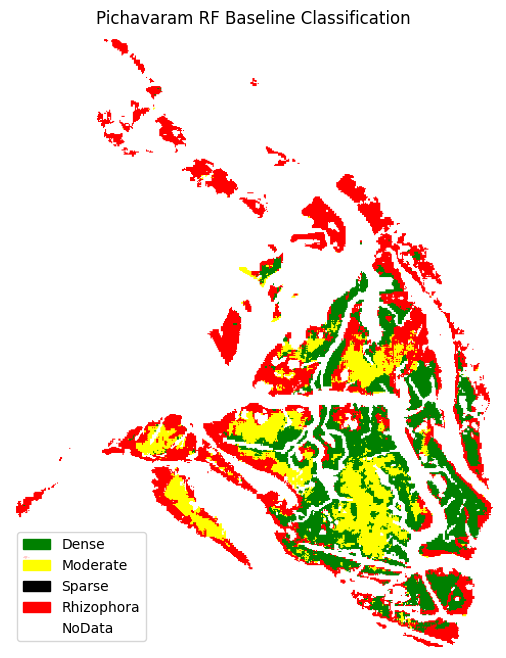

In [23]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

cmap = ListedColormap([
    "green",   # Dense
    "yellow",  # Moderate
    "black",   # Sparse
    "red",     # Rhizophora
    "white"    # NoData
])

display_map = species_map.copy()
display_map[display_map == 255] = 5

plt.figure(figsize=(10, 8))

plt.imshow(display_map, cmap=cmap)

legend = [
    Patch(color="green", label="Dense"),
    Patch(color="yellow", label="Moderate"),
    Patch(color="black", label="Sparse"),
    Patch(color="red", label="Rhizophora"),
    Patch(color="white", edgecolor="black", label="NoData")
]

plt.legend(
    handles=legend,
    loc="lower left",
    fontsize=10
)

plt.title("Pichavaram RF Baseline Classification")

plt.axis("off")

plt.savefig(
    os.path.join(FIG_FOLDER, "Baseline_Classification.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()